# CRC Atera 教程 02：上皮注释区域与周边细胞组成

**目标**：复用肾脏案例的区域—距离带方法，但把“足细胞支持的肾小球”改成“CRC 官方 broad 上皮注释支持的候选区域”。

**这不是**：肿瘤病理分割、恶性细胞识别、肿瘤侵袭前沿或因果关系分析。当前只有一个样本；距离带内的大量细胞不是独立患者重复。

请先完整运行教程 01。本教程读取它保存的轻量空间注释表，不需要重复载入全表达矩阵。

## 1. 方法地图：指定什么，验证什么？

```text
官方 azimuth_broad == 'Epithelial cell'
                  ↓ 259,898 个种子细胞（由教程 01 保存）
     alpha shape + 去除孔洞 + 连通分量
                  ↓ 每区域至少 30 个种子细胞
          候选上皮注释区域（不是肿瘤边界）
                  ↓ 25 µm 带宽；向内/向外各 200 µm
 全部细胞的 broad 注释：上皮、成纤维、免疫、其他/未分配
```

`inv_alpha` 单位为 µm；**数值越大，alpha shape 的 alpha 越小，轮廓通常越宽松**。本次先比较 `20/40/80 µm`，再固定 `40 µm` 演示，而不是照搬肾脏后声称它是 CRC 最优值。

- `MIN_SEED_CELLS=30`：本教程的探索性稳定度门槛，不是组织学标准。
- 细胞组成基于 Celldega `calc_gradient` 的区域间全局距离带；相邻区域会合并，可能混合不同区域。
- `clip_reference=spatial_cells, clip_alpha=200`：外带裁到由细胞坐标得到的近似组织轮廓，不是组织病理标注。
- 采用 `intersects` 空间连接；多个候选匹配按 `dist_start_um` 排序，保留更靠内的一条。这与肾脏教程一致，是预注册的分析选择，不是距离几何的唯一方案。

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely import union_all
from shapely.geometry import Polygon, Point
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

MODULE_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'scripts' / 'atera_helpers.py').is_file()
                   and p.name == 'crc-atera-learning'), None)
assert MODULE_DIR is not None, '请从 crc-atera-learning 目录运行 notebook'
sys.path.insert(0, str(MODULE_DIR / 'scripts'))
from atera_helpers import write_software_record
import celldega as dega

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.titlesize': 11, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'figure.dpi': 120, 'savefig.dpi': 300,
    'axes.spines.top': False, 'axes.spines.right': False,
})
OUTPUT_DIR = MODULE_DIR / 'output' / 'epithelial_gradient'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED_FIELD = 'azimuth_broad'
SEED_LABEL = 'Epithelial cell'
MIN_SEED_CELLS = 30
INV_ALPHA_UM = 40
INV_ALPHA_GRID_UM = [20, 40, 80]
BIN_WIDTH_UM = 25
MAX_DISTANCE_UM = 200
CLIP_ALPHA_UM = 200
CELL_TYPE = 'broad_group'
print('Celldega:', dega.__version__)
print('Seed:', SEED_FIELD, '==', SEED_LABEL)

Celldega: 0.27.0
Seed: azimuth_broad == Epithelial cell


## 2. 读取教程 01 的官方空间注释

`is_epithelial_seed` 来自**官方 broad 注释**，而不是 cluster 编号或恶性判定。保留所有细胞；`Unannotated` 与 `Unassigned` 分别保存。少量其他 broad 类型合并为 `Other assigned`，完整标签仍保留在 `azimuth_broad` 中。

In [2]:
spatial_cells = pd.read_parquet(MODULE_DIR / 'output' / 'tables' / '01_official_spatial_annotations.parquet').reset_index(drop=True)
assert spatial_cells['cell_id'].is_unique
assert spatial_cells[['centroid_column', 'centroid_row']].notna().all().all()
spatial_cells['is_epithelial_seed'] = spatial_cells['is_epithelial_seed'].astype(bool)
assert spatial_cells['is_epithelial_seed'].notna().all()
assert (spatial_cells[SEED_FIELD].astype(str).eq(SEED_LABEL) == spatial_cells['is_epithelial_seed']).all()
assert len(spatial_cells) == 446777
assert int(spatial_cells['is_epithelial_seed'].sum()) == 259898
seed_mask = spatial_cells['is_epithelial_seed'].to_numpy(dtype=bool)
assert seed_mask.dtype == np.dtype(bool) and not np.isnan(seed_mask).any()

xy = spatial_cells[['centroid_column', 'centroid_row']].to_numpy(dtype=float)
points = gpd.GeoDataFrame(
    spatial_cells.copy(),
    geometry=gpd.points_from_xy(xy[:, 0], xy[:, 1]),
)
# Keep cell_id as a column; a same-named row index breaks GeoPandas sjoin.
seed_cells = points.loc[points['is_epithelial_seed'].to_numpy(dtype=bool)]
points['broad_group'] = points['azimuth_broad'].astype(str).where(
    points['azimuth_broad'].astype(str).isin(['Epithelial cell', 'Fibroblast', 'Immune cell', 'Unannotated', 'Unassigned']),
    'Other assigned',
)
print('All cells:', f'{len(points):,}')
print('Official epithelial annotation seeds:', f'{len(seed_cells):,}')
print('Seed clusters (top 10):')
display(seed_cells['leiden_res_1.0'].value_counts().head(10).rename('n_seed_cells').to_frame())
print('Marker evidence is reported in tutorial 01; EPCAM/KRT positivity does not establish malignancy.')

All cells: 446,777
Official epithelial annotation seeds: 259,898
Seed clusters (top 10):


,n_seed_cells
leiden_res_1.0,
3,62879
15,28977
10,27231
19,25653
17,25041
18,21210
2,20964
5,15222
23,10269


Marker evidence is reported in tutorial 01; EPCAM/KRT positivity does not establish malignancy.


## 3. 从种子坐标生成候选区域

Alpha shape 是点集几何，不是病理分类器。孔洞填充沿用肾脏示例；它可能填入腺体腔隙或低信号区域。每个连通分量必须含至少 30 个种子细胞才保留，以降低零散误注释或孤立信号造成的小区域。

先查看 `inv_alpha=40 µm` 的结果，再在下一步比较其他尺度。

Candidate regions: 9
Seeds inside retained regions: 259,585 / 259,898


,n_seed_cells,seed_fraction,area_um2
count,9.00,9.00,9.00
mean,28842.78,0.11,4923176.22
std,86114.03,0.33,14717603.17
min,32.00,0.00,1490.52
25%,48.00,0.00,3564.35
50%,142.00,0.00,15593.45
75%,210.00,0.00,33135.67
max,258480.00,0.99,44170098.55


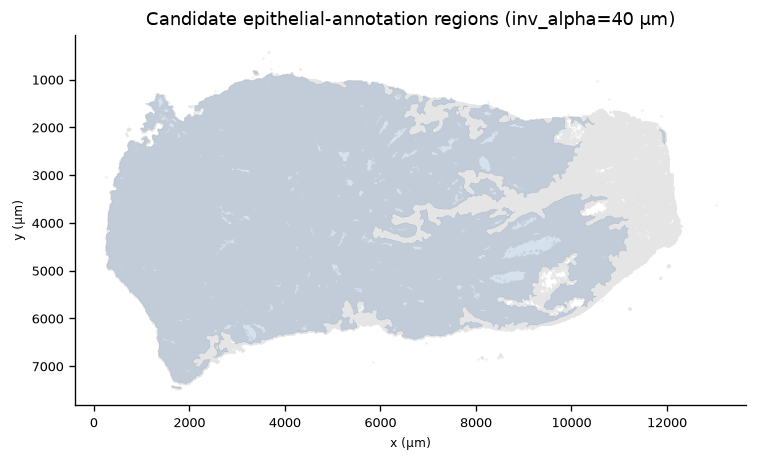

In [3]:
def make_candidate_regions(seed_xy, seed_points, inv_alpha, min_seed_cells):
    """Return labeled, hole-filled, seed-supported connected components in µm space."""
    shape = dega.nbhd.alpha_shape(seed_xy, inv_alpha=inv_alpha)
    assert not shape.is_empty, 'No alpha shape; inspect coordinates and parameter scale'
    # This deliberately follows the kidney tutorial: discard holes, then split components.
    filled = union_all([Polygon(polygon.exterior) for polygon in shape.geoms])
    regions = gpd.GeoDataFrame(geometry=[filled]).explode(index_parts=False).reset_index(drop=True)
    hits = seed_points.sjoin(regions, predicate='intersects')
    regions['n_seed_cells'] = hits['index_right'].value_counts().reindex(regions.index, fill_value=0)
    regions['n_seed_cells'] = regions['n_seed_cells'].astype(int)
    regions['seed_fraction'] = regions['n_seed_cells'] / len(seed_points)
    regions['area_um2'] = regions.geometry.area
    regions = regions.loc[regions['n_seed_cells'] >= min_seed_cells].copy().reset_index(drop=True)
    regions['name'] = [f'epithelial_region_{i + 1}' for i in range(len(regions))]
    regions['inv_alpha_um'] = inv_alpha
    regions['min_seed_cells'] = min_seed_cells
    regions['seed_definition'] = "official azimuth_broad == 'Epithelial cell'"
    assert regions.geometry.is_valid.all() and not regions.empty
    return regions

regions = make_candidate_regions(xy[seed_mask], seed_cells,
                                  INV_ALPHA_UM, MIN_SEED_CELLS)
print(f'Candidate regions: {len(regions):,}')
print(f'Seeds inside retained regions: {regions.n_seed_cells.sum():,} / {len(seed_cells):,}')
display(regions[['name', 'n_seed_cells', 'seed_fraction', 'area_um2']].describe().round(2))

fig, ax = plt.subplots(figsize=(6.2, 6.8), layout='constrained')
ax.scatter(xy[:, 0], xy[:, 1], s=.12, color='#e5e5e5', rasterized=True)
regions.plot(ax=ax, color='#4477aa', alpha=.22, edgecolor='#205080', linewidth=.25)
ax.set(xlabel='x (µm)', ylabel='y (µm)',
       title=f'Candidate epithelial-annotation regions (inv_alpha={INV_ALPHA_UM} µm)')
ax.set_aspect('equal'); ax.invert_yaxis()
plt.show()

## 4. 参数敏感性：先审计，再解释组成

比较相同种子和最少细胞数下的 `inv_alpha=20/40/80 µm`。看保留区域数、总面积和种子覆盖率，而不是选择让组成曲线最符合预期的参数。

若参数变化导致区域大面积合并/分裂或种子覆盖大幅改变，应把当前轮廓视为不稳定的几何近似。本教程不把其中任何一个称为“正确肿瘤边界”。

20 {'inv_alpha_um': 20, 'n_regions': 96, 'area_um2': np.float64(31943131.20451931), 'retained_seed_cells': 257832, 'seed_coverage': np.float64(0.9920507275931327)}


40 {'inv_alpha_um': 40, 'n_regions': 9, 'area_um2': np.float64(44308585.97041861), 'retained_seed_cells': 259585, 'seed_coverage': np.float64(0.9987956813826963)}


80 {'inv_alpha_um': 80, 'n_regions': 2, 'area_um2': np.float64(48621530.69623575), 'retained_seed_cells': 259794, 'seed_coverage': np.float64(0.9995998430153368)}


,inv_alpha_um,n_regions,area_um2,retained_seed_cells,seed_coverage
0,20,96,3.194313e+07,257832,0.9921
1,40,9,4.430859e+07,259585,0.9988
2,80,2,4.862153e+07,259794,0.9996


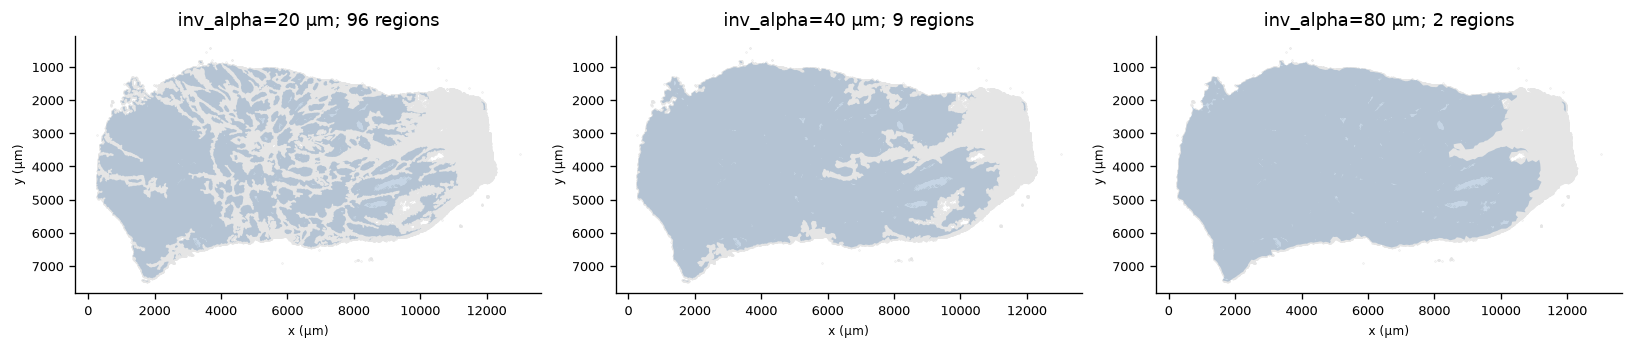

In [4]:
sensitivity_records = []
region_grid = {}
for candidate_alpha in INV_ALPHA_GRID_UM:
    candidate_regions = make_candidate_regions(
        xy[seed_mask], seed_cells, candidate_alpha, MIN_SEED_CELLS,
    )
    region_grid[candidate_alpha] = candidate_regions
    sensitivity_records.append({
        'inv_alpha_um': candidate_alpha, 'n_regions': len(candidate_regions),
        'area_um2': candidate_regions.geometry.area.sum(),
        'retained_seed_cells': int(candidate_regions['n_seed_cells'].sum()),
        'seed_coverage': candidate_regions['n_seed_cells'].sum() / len(seed_cells),
    })
    print(candidate_alpha, sensitivity_records[-1])
sensitivity = pd.DataFrame(sensitivity_records)
assert set(sensitivity.inv_alpha_um) == set(INV_ALPHA_GRID_UM)
display(sensitivity.round(4))
sensitivity.to_csv(OUTPUT_DIR / 'region_parameter_sensitivity.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), layout='constrained')
for ax, alpha_value in zip(axes, INV_ALPHA_GRID_UM):
    candidate_regions = region_grid[alpha_value]
    ax.scatter(xy[:, 0], xy[:, 1], s=.1, color='#e5e5e5', rasterized=True)
    candidate_regions.plot(ax=ax, color='#4477aa', alpha=.3, linewidth=0)
    ax.set(xlabel='x (µm)', ylabel='y (µm)',
           title=f'inv_alpha={alpha_value} µm; {len(candidate_regions)} regions')
    ax.set_aspect('equal'); ax.invert_yaxis()
fig.savefig(OUTPUT_DIR / 'region_parameter_sensitivity.png', bbox_inches='tight')
plt.show()

## 5. 构造距离带并检查局部几何

负距离：候选区域内部；0：区域边界；正距离：外部。多个区域先合并，再生成距离带，因此邻近区域之间不会重复生成独立环带，但可能把不同上皮结构的信号汇总在一起。

下面同时显示全切片与一块包含候选区域边界过渡的 1.2 mm 局部窗口。窗口按区域边界框筛选；相邻区域及距离带可以伸出窗口，本图不表示只存在一个完整区域。局部图只用于肉眼检查，不是参数优化。

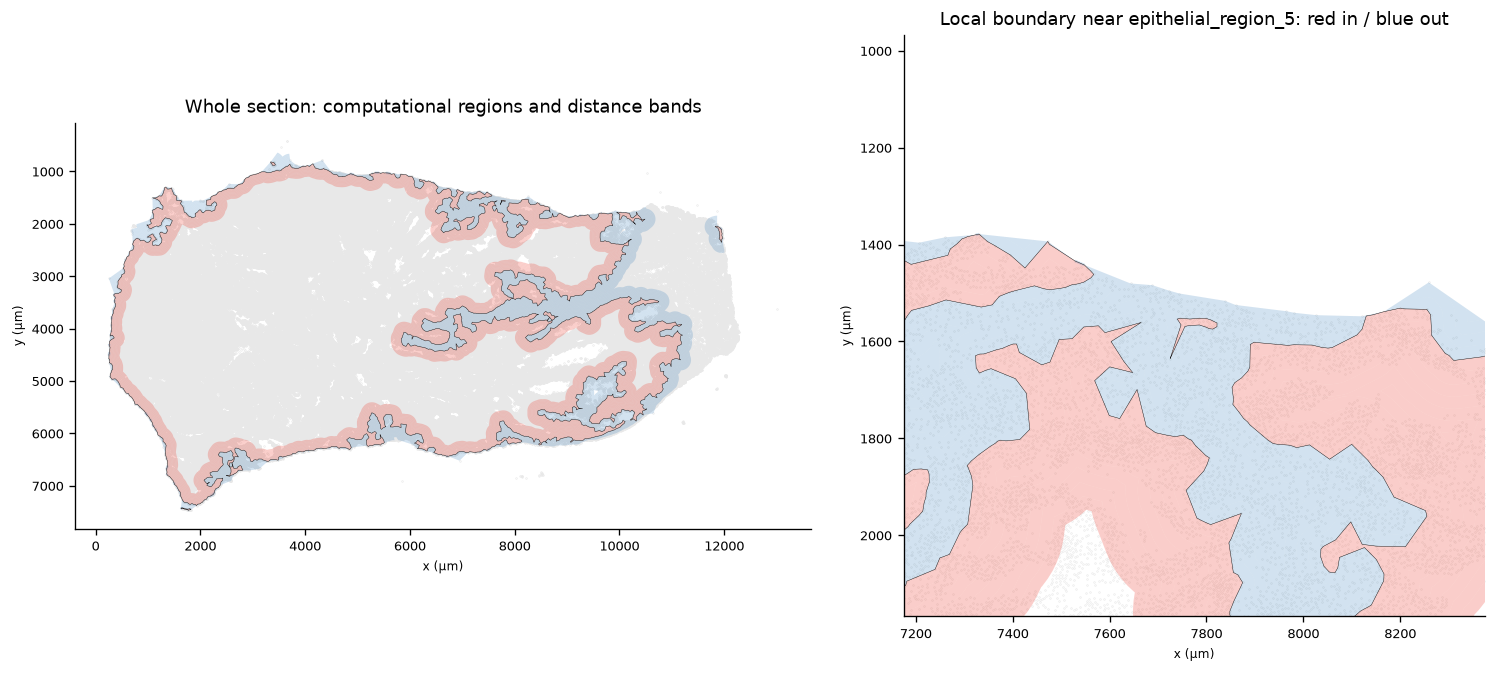

In [5]:
rings = dega.nbhd.calc_gradient(
    regions, direction='both', bin_width=BIN_WIDTH_UM, max_dist=MAX_DISTANCE_UM,
    clip_reference=xy, clip_alpha=CLIP_ALPHA_UM,
)
rings['distance_um'] = (rings['dist_start_um'] + rings['dist_end_um']) / 2
rings['analysis_definition'] = 'distance from computational epithelial-annotation region; not tumor front'
assert len(rings) > 0 and rings.geometry.is_valid.all()
assert set(rings.direction) == {'inward', 'outward'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained')
for ax in axes:
    ax.scatter(xy[:, 0], xy[:, 1], s=.1, color='#e8e8e8', rasterized=True)
    rings[rings.direction.eq('inward')].plot(ax=ax, color='#ef3b2c', alpha=.25)
    rings[rings.direction.eq('outward')].plot(ax=ax, color='#2171b5', alpha=.20)
    regions.boundary.plot(ax=ax, color='black', linewidth=.25)
    ax.set(xlabel='x (µm)', ylabel='y (µm)', aspect='equal')
    ax.invert_yaxis()
axes[0].set_title('Whole section: computational regions and distance bands')
# Choose a small region as a visual anchor. Adjacent bands may extend beyond this local window.
eligible = regions.loc[(regions.geometry.bounds.maxx - regions.geometry.bounds.minx).lt(700)
                       & (regions.geometry.bounds.maxy - regions.geometry.bounds.miny).lt(700)]
focus = eligible.geometry.centroid.iloc[int(eligible.geometry.area.idxmax())]
axes[1].set(xlim=(focus.x - 600, focus.x + 600), ylim=(focus.y + 600, focus.y - 600))
axes[1].set_title(f'Local boundary near {eligible.loc[eligible.geometry.area.idxmax(), "name"]}: red in / blue out')
fig.savefig(OUTPUT_DIR / 'distance_bands_overview.png', bbox_inches='tight')
plt.show()

# 读图问题：局部轮廓是否桥接了明显不同的上皮结构？填入的孔洞是什么？

## 6. 每个细胞只分配一次，统计粗细胞组成

这里使用 `points.sjoin(..., predicate='intersects')`，与肾脏教程相同；边界重复匹配按 `dist_start_um` 排序，保留更靠内的一条。

- 未落入距离带的细胞不进入比例分母。
- `Unannotated/Unassigned` 保留，不默认当低质量噪声删除。
- 每条带的比例总和应为 1（空带除外）；同时输出整数计数和细胞数。
- 比例汇总按**细胞加权**，不是先求每个区域的平均。

In [6]:
assigned = points.sjoin(
    rings[['name', 'dist_start_um', 'geometry']], predicate='intersects',
).sort_values('dist_start_um', kind='stable')
assigned = assigned.loc[~assigned.index.duplicated(keep='first')].copy()
assert assigned['cell_id'].is_unique
assert assigned['dist_start_um'].notna().all()
counts = pd.crosstab(assigned['name'], assigned[CELL_TYPE]).reindex(rings['name'], fill_value=0)
preferred = ['Epithelial cell', 'Fibroblast', 'Immune cell', 'Other assigned', 'Unannotated', 'Unassigned']
counts = counts.reindex(columns=[label for label in preferred if label in counts.columns], fill_value=0)
n_cells = counts.sum(axis=1)
proportions = counts.div(n_cells.replace(0, np.nan), axis=0).fillna(0)
assert (counts.to_numpy() >= 0).all()
assert np.allclose(proportions.loc[n_cells.gt(0)].sum(axis=1), 1)
assert len(assigned) == int(n_cells.sum())
print(f'{len(assigned):,} unique cells in {len(rings)} bands; {len(points) - len(assigned):,} cells outside bands')
display(pd.DataFrame({'distance_um': rings.set_index('name').distance_um, 'n_cells': n_cells}))

145,969 unique cells in 16 bands; 300,808 cells outside bands


,distance_um,n_cells
name,,
in (-175~-200) µm,-187.5,9722
in (-150~-175) µm,-162.5,9785
in (-125~-150) µm,-137.5,10531
in (-100~-125) µm,-112.5,10832
in (-75~-100) µm,-87.5,11670
in (-50~-75) µm,-62.5,13254
in (-25~-50) µm,-37.5,16921
in (0~-25) µm,-12.5,23767
out (+0~+25) µm,12.5,11289


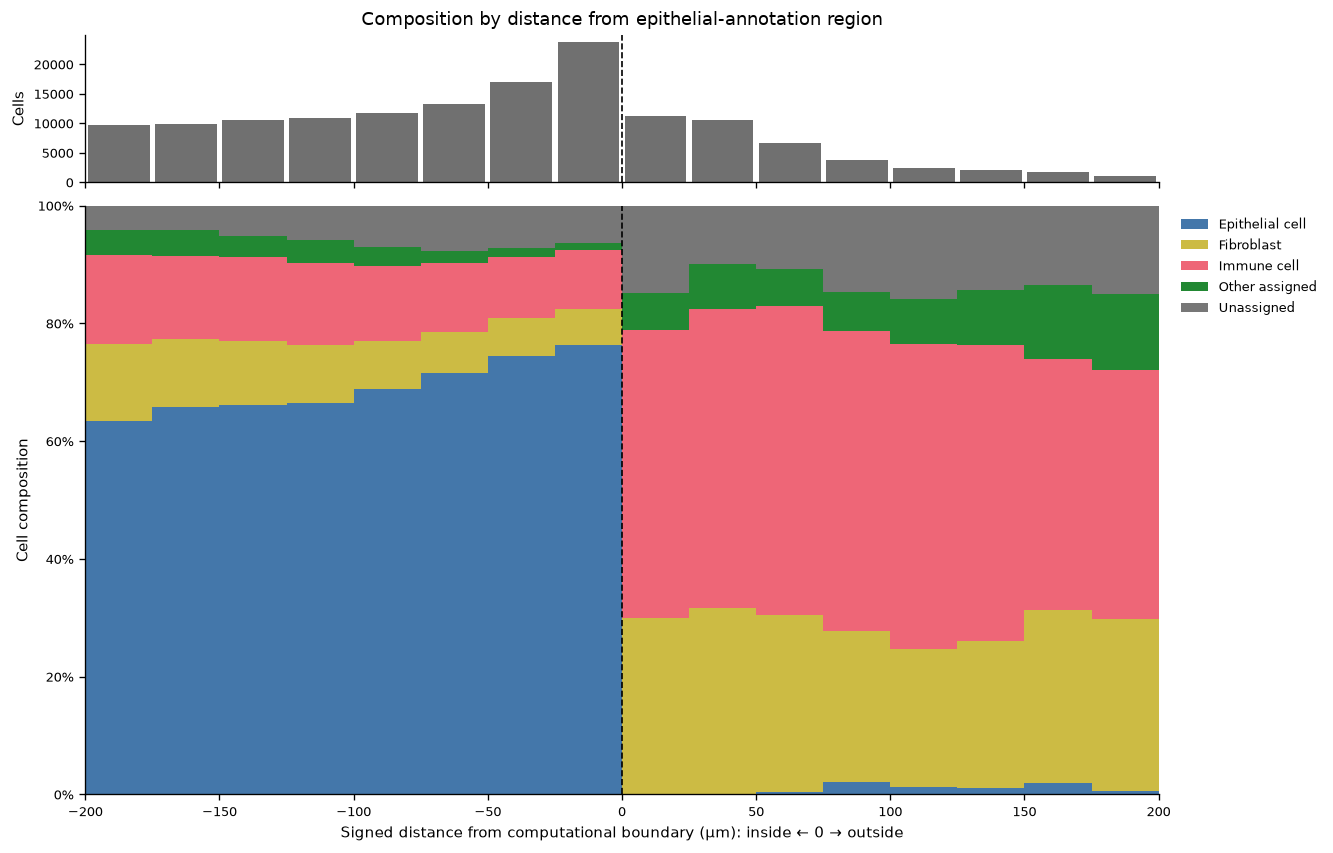

Observed composition (%); read the saved table for exact values:


broad_group,Epithelial cell,Fibroblast,Immune cell,Other assigned,Unassigned
name,,,,,
in (-175~-200) µm,63.34,13.12,15.17,4.29,4.07
in (-150~-175) µm,65.80,11.52,14.03,4.44,4.21
in (-125~-150) µm,66.18,10.86,14.29,3.54,5.13
in (-100~-125) µm,66.48,9.86,13.84,4.00,5.83
in (-75~-100) µm,68.88,8.05,12.81,3.26,7.00
in (-50~-75) µm,71.54,6.92,11.79,2.07,7.68
in (-25~-50) µm,74.46,6.41,10.47,1.41,7.26
in (0~-25) µm,76.28,6.22,9.95,1.10,6.44
out (+0~+25) µm,0.09,29.81,48.97,6.33,14.80


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                         gridspec_kw={'height_ratios': [1, 4]}, layout='constrained')
plot_rings = rings.set_index('name').loc[counts.index]
x = plot_rings.distance_um.to_numpy()
axes[0].bar(x, n_cells, width=BIN_WIDTH_UM * .92, color='#707070')
axes[0].set(ylabel='Cells', title='Composition by distance from epithelial-annotation region')
palette = {'Epithelial cell': '#4477aa', 'Fibroblast': '#ccbb44',
           'Immune cell': '#ee6677', 'Other assigned': '#228833',
           'Unannotated': '#bdbdbd', 'Unassigned': '#777777'}
bottom = np.zeros(len(proportions))
for cell_type in proportions:
    axes[1].bar(x, proportions[cell_type], bottom=bottom, width=BIN_WIDTH_UM,
                color=palette[cell_type], label=cell_type)
    bottom += proportions[cell_type].to_numpy()
for ax in axes:
    ax.axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(xlabel='Signed distance from computational boundary (µm): inside ← 0 → outside',
            ylabel='Cell composition', ylim=(0, 1),
            xlim=(plot_rings.dist_start_um.min(), MAX_DISTANCE_UM))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
fig.savefig(OUTPUT_DIR / 'epithelial_region_composition.png', bbox_inches='tight')
plt.show()
print('Observed composition (%); read the saved table for exact values:')
display(proportions.mul(100).round(2))

## 6b. 组成随轮廓参数变化吗？

相同的细胞、注释和距离定义，换用 20/40/80 µm 轮廓后重新生成距离带并分配细胞。`counts/proportions` 仍保留预设 40 µm 的结果，便于后续学习；参数比较表则完整记录三个尺度。若曲线不同，这是**几何定义敏感性**，不能择优当成肿瘤生物学结论。

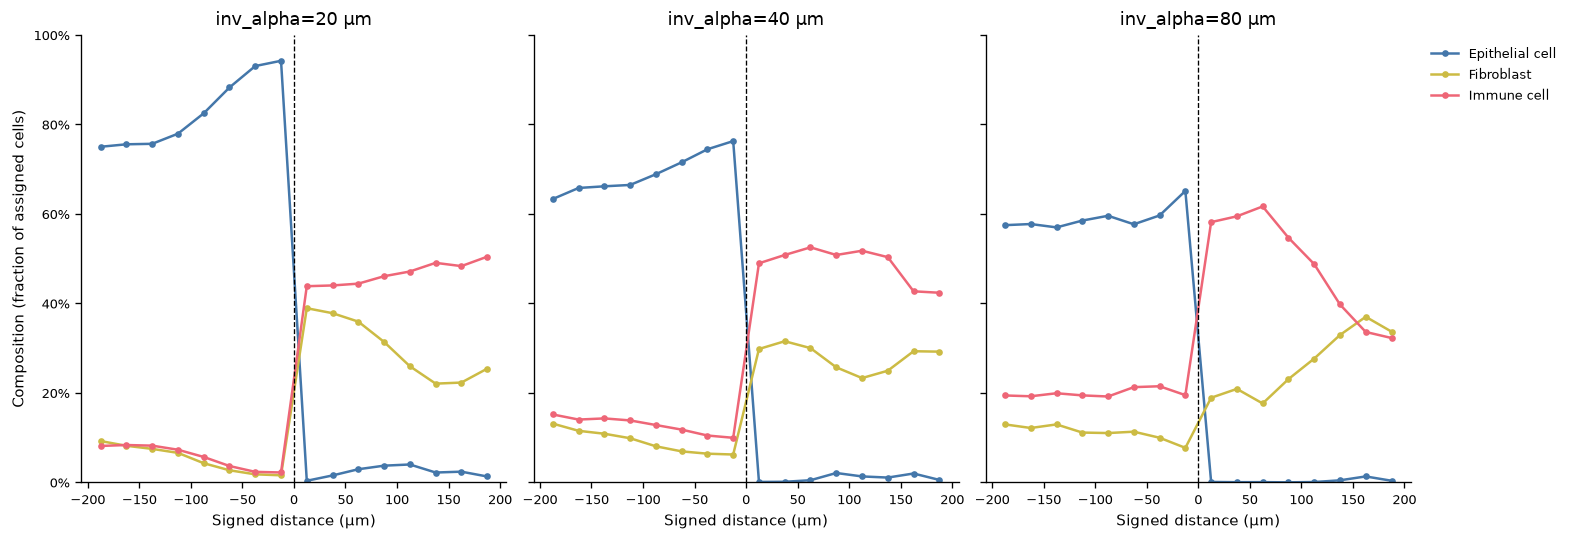

All three compositions use identical cell input and distance definitions; compare rather than cherry-pick.


In [8]:
sensitivity_compositions = []
for alpha_value in INV_ALPHA_GRID_UM:
    candidate_rings = dega.nbhd.calc_gradient(
        region_grid[alpha_value], direction='both', bin_width=BIN_WIDTH_UM,
        max_dist=MAX_DISTANCE_UM, clip_reference=xy, clip_alpha=CLIP_ALPHA_UM,
    )
    candidate_rings['distance_um'] = (candidate_rings.dist_start_um + candidate_rings.dist_end_um) / 2
    candidate_assigned = points.sjoin(
        candidate_rings[['name', 'dist_start_um', 'geometry']], predicate='intersects',
    ).sort_values('dist_start_um', kind='stable')
    candidate_assigned = candidate_assigned.loc[~candidate_assigned.index.duplicated(keep='first')]
    assert candidate_assigned.cell_id.is_unique
    candidate_counts = pd.crosstab(candidate_assigned['name'], candidate_assigned[CELL_TYPE]).reindex(
        candidate_rings['name'], fill_value=0).reindex(columns=counts.columns, fill_value=0)
    candidate_proportions = candidate_counts.div(candidate_counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
    for band_name, row in candidate_proportions.iterrows():
        sensitivity_compositions.append({
            'inv_alpha_um': alpha_value, 'band_name': band_name,
            'distance_um': candidate_rings.set_index('name').loc[band_name, 'distance_um'],
            'n_cells': int(candidate_counts.loc[band_name].sum()), **row.to_dict(),
        })
sensitivity_compositions = pd.DataFrame(sensitivity_compositions)
assert set(sensitivity_compositions.inv_alpha_um) == set(INV_ALPHA_GRID_UM)
sensitivity_compositions.to_csv(OUTPUT_DIR / 'composition_by_parameter_and_band.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True, layout='constrained')
for ax, alpha_value in zip(axes, INV_ALPHA_GRID_UM):
    subset = sensitivity_compositions.loc[sensitivity_compositions.inv_alpha_um.eq(alpha_value)]
    for cell_type in ['Epithelial cell', 'Fibroblast', 'Immune cell']:
        ax.plot(subset.distance_um, subset[cell_type], marker='o', markersize=3,
                label=cell_type, color=palette[cell_type])
    ax.axvline(0, color='black', linestyle='--', linewidth=.8)
    ax.set(xlabel='Signed distance (µm)', ylim=(0, 1),
           title=f'inv_alpha={alpha_value} µm')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel('Composition (fraction of assigned cells)')
axes[-1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
fig.savefig(OUTPUT_DIR / 'composition_parameter_sensitivity.png', bbox_inches='tight')
plt.show()
print('All three compositions use identical cell input and distance definitions; compare rather than cherry-pick.')

## 7. 保存结果和结论边界

本次输出只支持“在这张 CRC 切片中，官方上皮注释坐标构建的候选区域周边，官方 broad 注释组成如何随距离变化”。

它不支持：

- 该区域就是癌巢、该区域边界就是肿瘤—间质界面；
- 距离变化由侵袭或细胞通讯引起；
- 这些趋势能推广到其他 CRC 患者；
- 已验证 GHIST+ 预测表达或模型微调收益。

下一步若进入病理空间研究，需要病理 ROI/形态核对、配准、参数稳健性和独立样本验证。若继续 GHIST+，应先做小 ROI 的 H&E—核—表达对应和 M0 推理；本教程的官方空间坐标不能替代这一步。

In [9]:
counts.to_csv(OUTPUT_DIR / 'composition_counts_by_band.csv')
proportions.to_csv(OUTPUT_DIR / 'composition_proportions_by_band.csv')
rings.drop(columns='geometry').assign(area_um2=rings.geometry.area).to_csv(
    OUTPUT_DIR / 'distance_band_summary.csv', index=False)
regions.drop(columns='geometry').to_csv(OUTPUT_DIR / 'region_summary.csv', index=False)
# GeoParquet 保留几何；不会将整张表达矩阵稠密化或复制到这里。
regions.to_parquet(OUTPUT_DIR / 'epithelial_region_footprints.parquet')
rings.to_parquet(OUTPUT_DIR / 'epithelial_distance_bands.parquet')
assigned[['cell_id', 'barcode', 'centroid_column', 'centroid_row', 'azimuth_broad',
          'broad_group', 'leiden_res_1.0', 'name', 'dist_start_um']].to_parquet(
    OUTPUT_DIR / 'cell_band_assignments.parquet', index=False)
manifest = {
    'sample': 'Atera_v1_WTA_S4B_Colorectal_Cancer_FF',
    'n_input_cells': len(points), 'n_seed_cells': len(seed_cells),
    'seed_field': SEED_FIELD, 'seed_label': SEED_LABEL,
    'n_regions': len(regions), 'inv_alpha_um': INV_ALPHA_UM,
    'inv_alpha_grid_um': INV_ALPHA_GRID_UM,
    'min_seed_cells': MIN_SEED_CELLS, 'bin_width_um': BIN_WIDTH_UM,
    'max_distance_um': MAX_DISTANCE_UM, 'clip_alpha_um': CLIP_ALPHA_UM,
    'join_predicate': 'intersects', 'boundary_ties': 'more inward band',
    'n_assigned_cells': len(assigned), 'n_bands': len(rings),
    'alpha_sensitivity_regions': sensitivity.set_index('inv_alpha_um').n_regions.to_dict(),
    'composition_parameter_comparison': 'saved for all three inv_alpha settings; no best geometry claimed',
    'region_name': 'candidate epithelial-annotation region; not a tumor/pathology boundary',
    'biological_replicates': 1,
    'original_matrix_cell_filtering': 'none',
}
(OUTPUT_DIR / 'analysis_manifest.json').write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
write_software_record(OUTPUT_DIR / 'software_versions.json')
for required_file in ['region_parameter_sensitivity.csv', 'distance_bands_overview.png',
                      'epithelial_region_composition.png', 'composition_counts_by_band.csv',
                      'analysis_manifest.json']:
    assert (OUTPUT_DIR / required_file).is_file(), required_file
print(json.dumps(manifest, ensure_ascii=False, indent=2))

{
  "sample": "Atera_v1_WTA_S4B_Colorectal_Cancer_FF",
  "n_input_cells": 446777,
  "n_seed_cells": 259898,
  "seed_field": "azimuth_broad",
  "seed_label": "Epithelial cell",
  "n_regions": 9,
  "inv_alpha_um": 40,
  "inv_alpha_grid_um": [
    20,
    40,
    80
  ],
  "min_seed_cells": 30,
  "bin_width_um": 25,
  "max_distance_um": 200,
  "clip_alpha_um": 200,
  "join_predicate": "intersects",
  "boundary_ties": "more inward band",
  "n_assigned_cells": 145969,
  "n_bands": 16,
  "alpha_sensitivity_regions": {
    "20": 96,
    "40": 9,
    "80": 2
  },
  "composition_parameter_comparison": "saved for all three inv_alpha settings; no best geometry claimed",
  "region_name": "candidate epithelial-annotation region; not a tumor/pathology boundary",
  "biological_replicates": 1,
  "original_matrix_cell_filtering": "none"
}


## 学习检查

1. 如果只想把种子改成某个 Leiden cluster，应修改哪里？修改后为什么必须重新检查 cluster 的注释和 marker？
2. `inv_alpha` 增大时，区域如何变化？是否稳定？
3. 为什么本图不能命名为“肿瘤侵袭前沿细胞组成”？
4. 为什么 44 万个细胞不等于 44 万个独立样本？
5. 若要把细胞点叠加到 H&E，还缺哪一步验证？